In [ ]:
   !pip install transformers datasets accelerate scikit-learn

In [ ]:
from datasets import load_dataset
from transformers import AutoTokenizer

ds = load_dataset("mteb/RuReviewsClassification")
model_name = "cointegrated/rubert-tiny2"
tokenizer = AutoTokenizer.from_pretrained(model_name)

example = "Платье красивое, но села после стирки"
print(tokenizer.tokenize(example))
print(tokenizer(example)["input_ids"])

def tokenize(batch):
  return tokenizer(batch["text"], truncation=True, max_length=128)

tokenized = ds.map(tokenize, batched=True)


['Плат', '##ье', 'красивое', ',', 'но', 'села', 'после', 'стир', '##ки']
[2, 35176, 5976, 58268, 16, 1363, 3226, 1781, 69888, 954, 3]


Map:   0%|          | 0/45000 [00:00<?, ? examples/s]

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2048 [00:00<?, ? examples/s]

In [3]:
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding
import numpy as np
from sklearn.metrics import accuracy_score, f1_score

# 1. данные и токенизатор
ds = load_dataset("mteb/RuReviewsClassification")
model_name = "cointegrated/rubert-tiny2"
tokenizer = AutoTokenizer.from_pretrained(model_name)

# 2. токенизация
def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

tokenized = ds.map(tokenize, batched=True)

# 3. модель, collator, метрики
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)
data_collator = DataCollatorWithPadding(tokenizer)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "macro_f1": f1_score(labels, preds, average="macro"),
    }

README.md:   0%|          | 0.00/5.99k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 5.82MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.94MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Map:   0%|          | 0/2048 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [4]:
def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=128)

tokenized = ds.map(tokenize, batched=True)

from transformers import TrainingArguments, Trainer

args = TrainingArguments(
    output_dir="rubert_test",
    num_train_epochs=1,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    learning_rate=5e-5,
    report_to="none",
)

small_train = tokenized["train"].shuffle(seed=42).select(range(2000))
small_val = tokenized["validation"].shuffle(seed=42).select(range(1000))

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=small_train,
    eval_dataset=small_val,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()
print(trainer.evaluate())

Step,Training Loss


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Step,Accuracy,Macro F1
No log,0.958095,63,0.650000,0.644019


{'eval_loss': 0.958094596862793, 'eval_accuracy': 0.65, 'eval_macro_f1': 0.6440188416634132}


In [5]:
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=3)

args = TrainingArguments(
  output_dir="rubert_sentiment",
  num_train_epochs=3,
  per_device_train_batch_size=32,
  per_device_eval_batch_size=64,
  learning_rate=5e-5,
  eval_strategy="epoch",
  save_strategy="epoch",
  load_best_model_at_end=True,
  metric_for_best_model="macro_f1",
  report_to="none",
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

trainer.train()

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.583839,0.557092,0.751933,0.753377
2,0.510247,0.547416,0.756933,0.759564
3,0.469285,0.555476,0.760867,0.762817


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=4221, training_loss=0.5315208064524152, metrics={'train_runtime': 184.8433, 'train_samples_per_second': 730.348, 'train_steps_per_second': 22.836, 'total_flos': 219382914928032.0, 'train_loss': 0.5315208064524152, 'epoch': 3.0})

In [6]:
from sklearn.metrics import classification_report

output = trainer.predict(tokenized["validation"])
preds = np.argmax(output.predictions, axis=-1)
print(classification_report(output.label_ids, preds))

trainer.save_model("final_model")
tokenizer.save_pretrained("final_model")

              precision    recall  f1-score   support

           0       0.76      0.73      0.74      5000
           1       0.65      0.70      0.67      5000
           2       0.89      0.85      0.87      5000

    accuracy                           0.76     15000
   macro avg       0.77      0.76      0.76     15000
weighted avg       0.77      0.76      0.76     15000



Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('final_model/tokenizer_config.json', 'final_model/tokenizer.json')

In [7]:
!zip -r final_model.zip final_model

  adding: final_model/ (stored 0%)
  adding: final_model/tokenizer.json (deflated 73%)
  adding: final_model/training_args.bin (deflated 53%)
  adding: final_model/config.json (deflated 54%)
  adding: final_model/model.safetensors (deflated 8%)
  adding: final_model/tokenizer_config.json (deflated 51%)


In [13]:
!ls -lh /content/drive/MyDrive/final_model.zip

-rw------- 1 root root 104M Oct  6 09:59 /content/drive/MyDrive/final_model.zip


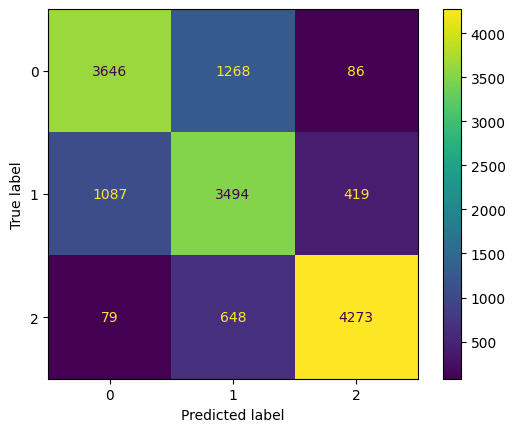

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(output.label_ids, preds)

In [16]:
import pandas as pd

val_df = ds["validation"].to_pandas()
val_df["pred"] = preds
errors = val_df[val_df["label"] != val_df["pred"]]

print(len(errors))
pd.set_option("display.max_colwidth", 300)
errors.sample(15, random_state=1)

3587


,text,label,pred
4872,"Пришёл быстро,две недели. Тонкий,синтетика. Капюшон маленький, он для красоты. Размер подошёл хорошо,не висит ,и не маловат. Торчат нитки,рукав сшит не правильно,это большой минус.",2,1
5191,"Пижама оказалась бракованная, прям на рисунке дырка и стрелка... Открыла спор, продавец молодец, деньги вернул без всякого...",1,0
448,Не стоит этих денег. Синтетика.,2,1
14966,Ткань не очень! Выкройка не очень!,1,0
4540,МАЛО в груди.ОГ-102 .Вот как то так! Брала на 2 размера больше.,1,2
11313,"по отслеживанию он как бы доставлен, но на почте его нет",1,0
3279,"к сожалению полное гавно платье,сшито как попало,просвечивает и цвет не соответствует картинке",1,0
1760,продавец не сразу отправил желал мне счастливой жизни постоянно общение вообще не понравилось футболка так себе материал приятный но не хлопок первая стирка и рисунок будет тусклым лучше бы не заказывала заказ не отслеживался вообще,0,1
5523,"У меня размер s (это важно), но просила заказать сестра, у неё 3й размер груди. По таблице размеров представленной продавцом она определила, что у неё размер L. Заказали. Пришло быстро, буквально за месяц. НО на 3й размер эта красота не налезет. На фото я",0,1
6459,"Тонкое платье,больше похоже на водолазку. На 42 русский заказала L-почти в обтяг.",2,1


In [17]:
pd.crosstab(val_df["label"], val_df["pred"])

pred,0,1,2
label,,,
0,3646,1268,86
1,1087,3494,419
2,79,648,4273


In [18]:
from sklearn.metrics import classification_report

test_out = trainer.predict(tokenized["test"])
test_preds = np.argmax(test_out.predictions, axis=-1)
print(classification_report(test_out.label_ids, test_preds))

              precision    recall  f1-score   support

           0       0.76      0.73      0.74       682
           1       0.65      0.69      0.67       683
           2       0.89      0.88      0.89       683

    accuracy                           0.77      2048
   macro avg       0.77      0.77      0.77      2048
weighted avg       0.77      0.77      0.77      2048



In [22]:
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

data = load_dataset("mteb/RuReviewsClassification")
tr = data["train"].to_pandas()
va = data["validation"].to_pandas()
te = data["test"].to_pandas()

tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2))
X_tr = tfidf.fit_transform(tr["text"])
X_va = tfidf.transform(va["text"])
X_te = tfidf.transform(te["text"])

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_tr, tr["label"])

print("VALIDATION")
print(classification_report(va["label"], lr_model.predict(X_va)))
print("TEST")
print(classification_report(te["label"], lr_model.predict(X_te)))

VALIDATION
              precision    recall  f1-score   support

           0       0.74      0.71      0.72      5000
           1       0.63      0.68      0.65      5000
           2       0.87      0.84      0.86      5000

    accuracy                           0.74     15000
   macro avg       0.75      0.74      0.74     15000
weighted avg       0.75      0.74      0.74     15000

TEST
              precision    recall  f1-score   support

           0       0.75      0.72      0.73       682
           1       0.64      0.67      0.66       683
           2       0.88      0.87      0.87       683

    accuracy                           0.75      2048
   macro avg       0.76      0.75      0.75      2048
weighted avg       0.76      0.75      0.75      2048



In [24]:
import numpy as np

my_reviews = [
    "Не плохо, но могло быть лучше",
    "Не ожидала, что будет так хорошо",
    "Размер не подошел, возвращаю",
    "Платье красивое, но села после стирки",
]

print("baseline:", lr_model.predict(tfidf.transform(my_reviews)))

enc = tokenizer(my_reviews, truncation=True, max_length=128, padding=True, return_tensors="pt")
enc = {k: v.to(model.device) for k, v in enc.items()}

with torch.no_grad():
    logits = model(**enc).logits
print("нейросеть:", logits.argmax(dim=-1).cpu().numpy())

baseline: [1 2 1 2]
нейросеть: [1 1 1 2]
